[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/higher_order.ipynb)

# Higher-order correlations

Order 1 is the dynamic correlations of the data, order 2 the dynamic correlations of features made from order 1, and so on. This notebook explains the two paths that `tc.features` follows, shows how to control each step, and recovers a signal injected at order 2. The method is from Owen, Chang & Manning (2021), *Nature Communications* 12, 5728 ([doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)), Fig. 10.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere).
# If the install from PyPI fails, it falls back to GitHub master.
import sys
if "google.colab" in sys.modules:
    !pip install -q "timecorr>=0.3.0" 2>/dev/null || pip install -q "timecorr @ git+https://github.com/ContextLab/timecorr.git@master"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import timecorr as tc

%matplotlib inline
# one style for every tutorial: colorblind-safe colors (Okabe-Ito)
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00', '#56B4E9', '#CC79A7', '#000000']
plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.prop_cycle': plt.cycler(color=COLORS), 'legend.frameon': False,
})

## 1. Two paths

Each order has two paths that start from the previous order's **feeding** features `D_{k-1}` (`D_0` is the data):

- the **analysis path** gives the features of order `k`: `X_k = rfun(timecorr(D_{k-1}))`;
- the **feeding path** gives the input of the next order: `D_k = delta_rfun(timecorr(D_{k-1}, feeding kernel, cfun=autofc))`.

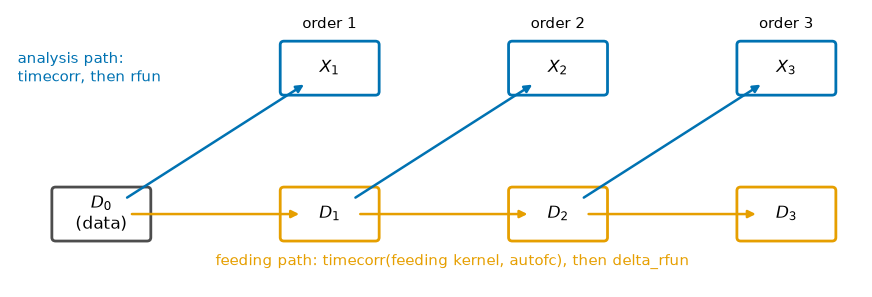

In [3]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.set(xlim=(-1.2, 10), ylim=(-1, 2.8))
ax.axis('off')

def box(x, y, text, color):
    ax.add_patch(FancyBboxPatch((x - 0.6, y - 0.32), 1.2, 0.64, boxstyle='round,pad=0.05',
                                fc='white', ec=color, lw=2))
    ax.text(x, y, text, ha='center', va='center', fontsize=12)

def arrow(x0, y0, x1, y1, color):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle='-|>', color=color, lw=1.8, shrinkA=22, shrinkB=22))

xs = [0, 3, 6, 9]
box(0, 0, '$D_0$\n(data)', '0.3')
for k in range(1, 4):
    box(xs[k], 2, f'$X_{k}$', COLORS[0])
    box(xs[k], 0, f'$D_{k}$', COLORS[1])
    arrow(xs[k - 1], 0, xs[k], 2, COLORS[0])
    arrow(xs[k - 1], 0, xs[k], 0, COLORS[1])
    ax.text(xs[k], 2.55, f'order {k}', ha='center')
ax.text(-1.1, 2, 'analysis path:\ntimecorr, then rfun', color=COLORS[0], va='center')
ax.text(1.5, -0.7, 'feeding path: timecorr(feeding kernel, autofc), then delta_rfun', color=COLORS[1])
plt.show()

The feeding path smooths once per order with its own kernel (by default a Gaussian of variance 25, narrower than the analysis kernel's default of 100), and the analysis kernel smooths each order's features once more.

## 2. `tc.features` and what each step did

`tc.features(data, order=n)` returns `[X_0, ..., X_n]`, and with `return_info=True` also one record per step and path (the reducer requested and the one used, and the widths). We use data from `tc.simulate_nested` (see the [simulation tutorial](simulate.ipynb)) and within-subject correlations (`cfun=tc.autofc`).

In [4]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

data, truth = tc.simulate_nested(S=2, T=1000, set_random_seed=0)
X, info = tc.features(data, order=2, cfun=tc.autofc, return_info=True)
print('widths:', [x[0].shape[1] for x in X])
columns = ['order', 'path', 'requested', 'effective', 'input_width', 'output_width']
print(pd.DataFrame(info)[columns].to_string(index=False))

widths: [108, 108, 36]
 order     path requested                                                                 effective  input_width  output_width
     1 analysis      auto                                                                       PCA          108           108
     1  feeding      auto                               Communities(n=None, signed=False, n_null=5)          108            18
     2 analysis      auto WeightedStrength(split=False, signed=True, n=None, n_null=5, center=True)           18            36


`tc.two_path_step` computes one step. Feeding its `D` to the next call gives the next order, the same as `tc.features`.

In [5]:
X1, D1 = tc.two_path_step(data, cfun=tc.autofc)
X2, D2 = tc.two_path_step(D1, cfun=tc.autofc, order=2)
print('step by step equals features:',
      all(np.allclose(a, b) for a, b in zip(X2, X[2])) and all(np.allclose(a, b) for a, b in zip(X1, X[1])))

step by step equals features: True


## 3. Reducers and kernels by order

`rfun`, `delta_rfun`, `weights_params` and `delta_weights_params` accept a dict keyed by order. Orders missing from the dict use the defaults. `delta_weights_function` sets the feeding kernel.

In [6]:
X, info = tc.features(data, order=2, cfun=tc.autofc, return_info=True,
                      rfun={1: 'PCA', 2: tc.WeightedStrength()},
                      weights_params={1: {'var': 100}, 2: {'var': 33 ** 2}})
print(pd.DataFrame(info)[['order', 'path', 'effective', 'output_width']].to_string(index=False))

 order     path                                                                  effective  output_width
     1 analysis                                                                        PCA           108
     1  feeding                                Communities(n=None, signed=False, n_null=5)            18
     2 analysis WeightedStrength(split=False, signed=False, n=None, n_null=5, center=True)            18


`include_timepoints` and `include_zero` make the kernels one-sided, as in the [kernels tutorial](kernels.ipynb). In `tc.features` they shape the feeding kernel too, unless it is `tc.eye_weights`.

In [7]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    backward = tc.features(data, order=2, cfun=tc.autofc, include_timepoints='backward')
print('widths with backward kernels:', [x[0].shape[1] for x in backward])
for message in sorted({str(w.message) for w in caught}):
    print('warning:', message)

widths with backward kernels: [108, 108, 36]


The first timepoints have too few past timepoints for a correlation (see the kernels tutorial).

## 4. Memory

Without reduction, `d` features become `d(d+1)/2` at every order. `estimate_memory_gb` (in `timecorr.higher_order`) estimates the peak memory of each order, and `tc.features` raises `MemoryError` before allocating when a step would need more than `max_memory_gb`.

In [8]:
from timecorr.higher_order import estimate_memory_gb

print('GB by order, 8 features, 1000 timepoints, unreduced:',
      [round(g, 3) for g in estimate_memory_gb(8, 3, 1000)])
try:
    tc.features(np.zeros((1000, 8)), order=3, rfun=None, delta_rfun=None, max_memory_gb=1)
except MemoryError as err:
    print('MemoryError:', err)

GB by order, 8 features, 1000 timepoints, unreduced: [0.0, 0.028, 0.108, 5.749]
MemoryError: Unreduced features at order 3 need about 5.75 GB (K=8, T=1000, 1 subject), more than max_memory_gb=1. The largest number of features that fits orders up to 3 is K=5. Pass a reducer (rfun, delta_rfun), lower the order, or raise max_memory_gb.


## 5. The original pipeline and structure at a chosen order

The pipeline of the paper uses PCA on both paths and co-fluctuations (the delta kernel, see the [kernels tutorial](kernels.ipynb)) on the feeding path, which is `rfun='PCA', delta_rfun=None, delta_weights_function=tc.eye_weights`.

In [9]:
X, info = tc.features(data, order=2, cfun=tc.autofc, return_info=True,
                      rfun='PCA', delta_rfun=None, delta_weights_function=tc.eye_weights)
print(pd.DataFrame(info)[['order', 'path', 'effective', 'output_width']].to_string(index=False))

 order     path effective  output_width
     1 analysis       PCA           108
     1  feeding       PCA           108
     2 analysis       PCA           108


With these co-fluctuations we can test recovery at a chosen order. `simulate_data(order=n)` hides a template at order `n` only, and `tc.carrier_reducer(blocks)` keeps just the products that carry it, so the run stays small. We score each analyzed order by the correlation between the estimated and true correlations.

In [10]:
p, T4 = 4, 1000
original = {'cfun': tc.autofc, 'weights_params': {'var': 625}, 'delta_weights_function': tc.eye_weights}

def score(Xk, cols, corrs):
    est = tc.vec2mat(Xk)[np.ix_(cols, cols, np.arange(Xk.shape[0]))]
    return np.corrcoef(tc.mat2vec(est)[:, p:].ravel(), corrs[:, p:].ravel())[0, 1]

def first_carriers(blocks, k, n):  # columns that hold each block's first carrier at order k
    return np.asarray(blocks)[:, 0] if k == 1 else np.arange(p) * 2 ** (n - k)

seeds, orders = [0, 1, 2], [1, 2, 3, 4]
r = {n: np.zeros((n, len(seeds))) for n in orders}
for s, seed in enumerate(seeds):
    for n in orders:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            d, t = tc.simulate_data(datagen='block', K=tc.min_features(n, p=p), T=T4, B=4, order=n,
                                    return_corrs=True, set_random_seed=seed)
        if seed == 0 and caught:
            print(f'order {n}:', caught[0].message)
        if n == 1:
            corrs, blocks, reducer = t, np.arange(p)[:, None], None
        else:
            corrs, blocks, reducer = t['corrs'], t['blocks'], tc.carrier_reducer(t['blocks'])
        Xn = tc.features(d, order=n, rfun=None, delta_rfun=reducer, **original)
        for k in range(1, n + 1):
            r[n][k - 1, s] = score(Xn[k], first_carriers(blocks, k, n), corrs)

for n in orders:
    print(f'hidden at order {n}: mean score by analyzed order', np.round(r[n].mean(1), 2))

order 3: The simulated structure exists only at order 3 (order >= 3). Variance-based reduction (for example PCA) may not retain it: in the higher-order tutorial's measurement at order 3 (20 seeds), PCA's event contrast was not distinguishable from its noise control (-0.00 versus 0.02, p = 0.20); orders above 3 were not measured. Analyze these data with delta_rfun=carrier_reducer(blocks) or without reduction (rfun=None).
order 4: The simulated structure exists only at order 4 (order >= 3). Variance-based reduction (for example PCA) may not retain it: in the higher-order tutorial's measurement at order 3 (20 seeds), PCA's event contrast was not distinguishable from its noise control (-0.00 versus 0.02, p = 0.20); orders above 3 were not measured. Analyze these data with delta_rfun=carrier_reducer(blocks) or without reduction (rfun=None).


hidden at order 1: mean score by analyzed order [0.92]
hidden at order 2: mean score by analyzed order [-0.13  0.92]
hidden at order 3: mean score by analyzed order [0.08 0.03 0.92]
hidden at order 4: mean score by analyzed order [-0.04 -0.07 -0.03  0.92]


The warning (for orders 3 and up) says that PCA may lose structure that exists only at those orders; `carrier_reducer` is used here instead. The bars show that the template is found at its own order and not below it.

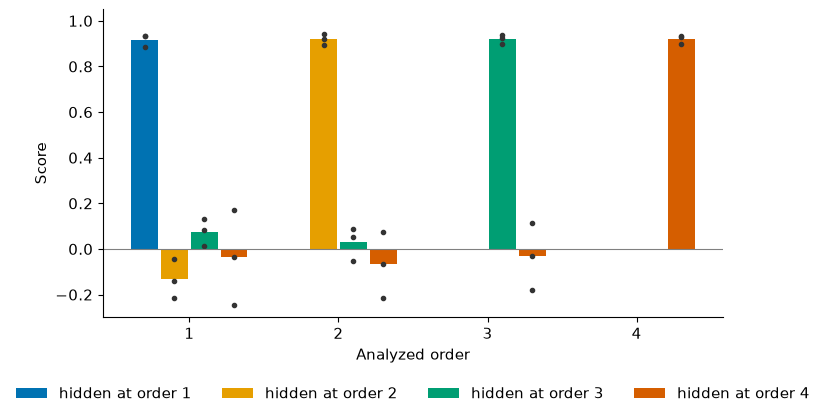

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, n in enumerate(orders):
    x = np.arange(1, n + 1) + (i - 1.5) * 0.2
    ax.bar(x, r[n].mean(1), 0.18, label=f'hidden at order {n}')
    for xi, row in zip(x, r[n]):
        ax.plot(np.full(len(seeds), xi), row, 'o', ms=3, color='0.2')
ax.axhline(0, color='0.5', lw=0.8)
ax.set(xticks=orders, xlabel='Analyzed order', ylabel='Score', ylim=(-0.3, 1.05))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=4)
plt.show()

### Does PCA keep structure that exists only at a high order?

PCA keeps the directions of largest variance, which need not hold structure that exists only at a high order. Without knowing the carriers, we measure the **event contrast** of block data, which is how much more similar the features of two timepoints are when they are in the same event than in different events, at equal distances in time. Each reducer is also run on Gaussian noise of the same shape, as its control (20 seeds).

In [12]:
from scipy import stats

T3, B3 = 600, 4
event = np.repeat(np.arange(B3), T3 // B3)

def event_contrast(Xk):
    S = np.corrcoef(Xk[:, Xk.std(axis=0) > 0])  # timepoint-by-timepoint similarity
    diffs = []
    for lag in range(1, T3):
        i = np.arange(T3 - lag)
        same = event[i] == event[i + lag]
        if same.any() and (~same).any():
            diffs.append(S[i, i + lag][same].mean() - S[i, i + lag][~same].mean())
    return np.mean(diffs)

for n in (2, 3):
    rows = {'carrier_reducer': [], 'carrier_reducer, noise': [], 'PCA': [], 'PCA, noise': []}
    for seed in range(20):
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='The simulated structure')  # printed above
            d, t = tc.simulate_data(datagen='block', K=tc.min_features(n, p=p), T=T3, B=B3, order=n,
                                    return_corrs=True, set_random_seed=seed)
        noise = np.random.default_rng(100 + seed).standard_normal(d.shape)
        for suffix, x in [('', d), (', noise', noise)]:
            rows['carrier_reducer' + suffix].append(event_contrast(tc.features(
                x, order=n, rfun=None, delta_rfun=tc.carrier_reducer(t['blocks']), **original)[n]))
            rows['PCA' + suffix].append(event_contrast(tc.features(
                x, order=n, rfun='PCA', delta_rfun=None, **original)[n]))
    for name, v in rows.items():
        print(f'order {n}  {name:24s} mean contrast {np.mean(v):6.2f}')
    welch = stats.ttest_ind(rows['PCA'], rows['PCA, noise'], equal_var=False)
    print(f'order {n}  PCA vs its noise control: Welch t = {welch.statistic:.2f}, p = {welch.pvalue:.3f}\n')

order 2  carrier_reducer          mean contrast   0.47
order 2  carrier_reducer, noise   mean contrast   0.00
order 2  PCA                      mean contrast   0.21
order 2  PCA, noise               mean contrast   0.08
order 2  PCA vs its noise control: Welch t = 3.08, p = 0.004



order 3  carrier_reducer          mean contrast   0.48
order 3  carrier_reducer, noise   mean contrast   0.03
order 3  PCA                      mean contrast  -0.00
order 3  PCA, noise               mean contrast   0.02
order 3  PCA vs its noise control: Welch t = -1.31, p = 0.200



`carrier_reducer` separates the events at both orders. PCA keeps part of the structure at order 2, but at order 3 its contrast does not differ from its noise control (p above). For this reason `simulate_data(order=n)` warns for `n >= 3`.

## 6. Recovering an injected order-2 signal

In `simulate_nested` data each supergroup has a slow strength `h` that lives in the correlations of its modules' couplings, an order-2 signal that the two subjects share. We learn a linear map from subject A's order-2 features to `h` and apply it to subject B. As a control, we apply the same map to a subject with a different `h`.

In [13]:
control, _ = tc.simulate_nested(S=2, T=1000, set_random_seed=1)
communities = tc.Communities()
Xn = tc.features([data[0], data[1], control[0]], order=2, cfun=tc.autofc,
                 weights_params={'var': 33 ** 2}, delta_rfun=communities)
print('communities found at order 1:', communities.fits_[0]['n'])

def zscore(x):
    return (x - x.mean(0)) / (x.std(0) + 1e-12)

def ridge_decode(XA, XB, y, step=10):
    A, B, y = zscore(XA[::step]), zscore(XB[::step]), y[::step]
    G = A @ A.T
    alpha = np.linalg.solve(G + np.trace(G) / len(G) * np.eye(len(G)), y - y.mean(0))
    pred = B @ (A.T @ alpha)
    return pred, np.mean([np.corrcoef(pred[:, c], y[:, c])[0, 1] for c in range(y.shape[1])])

h = truth['h']
pred, r_b = ridge_decode(Xn[2][0], Xn[2][1], h)
_, r_control = ridge_decode(Xn[2][0], Xn[2][2], h)
_, r_order1 = ridge_decode(Xn[1][0], Xn[1][1], h)
print(f'decode h, order 2, subject A -> B:       {r_b:.2f}')
print(f'decode h, order 2, subject A -> control: {r_control:.2f}')
print(f'decode h, order 1, subject A -> B:       {r_order1:.2f}')

communities found at order 1: 18
decode h, order 2, subject A -> B:       0.74
decode h, order 2, subject A -> control: -0.08
decode h, order 1, subject A -> B:       -0.36


These are raw scores for one seed. Over 24 seeds, `tests/test_nested_recovery.py` measured .751 +- .019 (mean +- standard error) for A -> B with this configuration, against -.025 +- .018 for the control. The order-1 features hold no information about `h` (.001 +- .046 over the same seeds, standard deviation .228), so the order-1 score above is within the spread of single seeds.

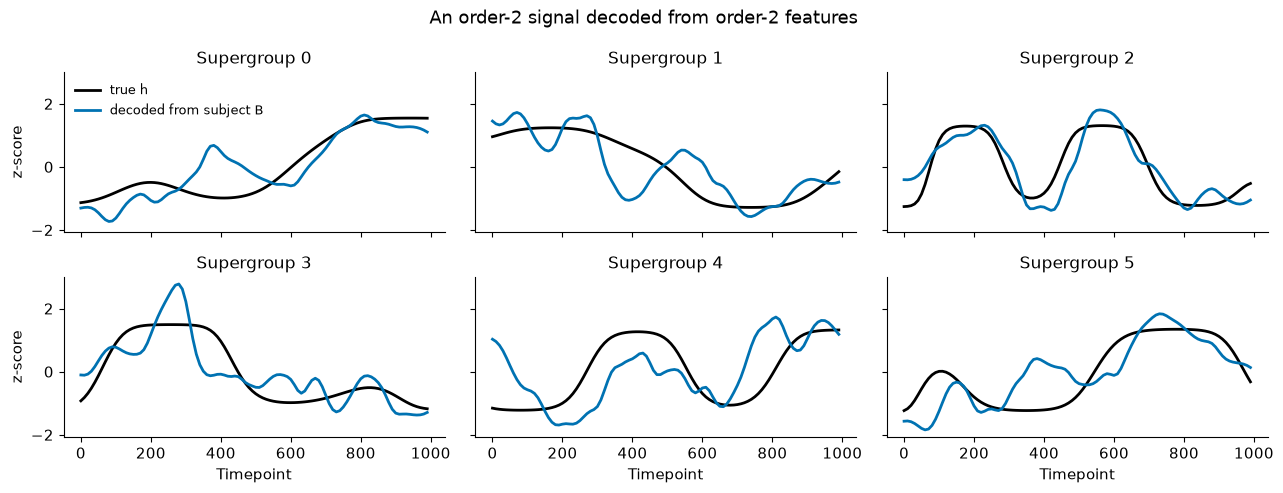

In [14]:
t = np.arange(0, 1000, 10)
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True, sharey=True)
for c, ax in enumerate(axes.ravel()):
    ax.plot(t, zscore(h[::10, c]), color='k', lw=2, label='true h')
    ax.plot(t, zscore(pred[:, c]), lw=2, label='decoded from subject B')
    ax.set_title(f'Supergroup {c}')
for ax in axes[1]:
    ax.set_xlabel('Timepoint')
for ax in axes[:, 0]:
    ax.set_ylabel('z-score')
axes[0, 0].legend(loc='upper left', fontsize=9)
fig.suptitle('An order-2 signal decoded from order-2 features')
fig.tight_layout()
plt.show()

Next: [event-restricted kernels](events.ipynb).